# Spoken-Word Recognition: the full ML cycle

**Problem:** voice-driven tools (hands-free devices, accessibility tools, learning apps) must recognise short spoken
words. This project classifies 1-second recordings of 8 spoken words (*yes, no, up, down, left, right, stop, go*)
from the public **Google Speech Commands** dataset, so an app can respond to a person's voice.
It is a proof of concept: the same pipeline can be retrained on recordings in another language
(for example Kinyarwanda) by changing only the data.

**Data type:** sound (.wav). **Model:** MobileNetV2 transfer learning on log-mel spectrograms,
compared with a vanilla CNN. The same code lives in `src/` and powers the API and UI.

Sections: 1 setup, 2 data acquisition, 3 exploration + interpretations, 4 preprocessing, 5 baseline,
6 optimised model, 7 evaluation, 8 prediction, 9 retraining demo, 10 conclusion.

## 1. Setup

In [1]:
import os, sys, random, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("/content/spoken-word-mlops"):
        os.system("git clone https://github.com/Queenlinda12/spoken-word-mlops.git /content/spoken-word-mlops")
    os.system("pip install -q librosa soundfile scikit-learn seaborn")
    os.chdir("/content/spoken-word-mlops")
elif os.path.basename(os.getcwd()) == "notebook":
    os.chdir("..")
sys.path.append(os.getcwd())
if not os.path.isdir("raw_recordings"):              # first run: download Google Speech Commands (~2.3 GB) and build the folders
    os.system(f"{sys.executable} scripts/prepare_speech_commands.py")

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, librosa, librosa.display
import tensorflow as tf
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, classification_report, roc_auc_score
from src import preprocessing as pp, model as mdl, prediction

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
EPOCHS = int(os.getenv("NB_EPOCHS", 15))
FT_EPOCHS = int(os.getenv("NB_FT_EPOCHS", 10))
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: []


## 2. Data acquisition
The data is the public **Google Speech Commands v0.02** dataset (Warden, 2018, CC BY 4.0): thousands of people saying
short words. `scripts/prepare_speech_commands.py` keeps 8 words and builds `raw_recordings/<word>/<speaker>__<n>.wav`
(40 speakers) plus `new_recordings/` (6 *different* speakers, used later for the retraining demo).
`split_raw_dataset` then builds `data/train` and `data/test`. With at least 4 speakers it **holds out whole speakers
for the test set**, so the test score measures how well the model understands a *new voice*, which is what matters in real use.

In [2]:
from pathlib import Path
RAW_DIR = os.getenv("RAW_DIR", "raw_recordings")     # <- one folder per word
assert os.path.isdir(RAW_DIR), f"'{RAW_DIR}' not found. Run scripts/prepare_speech_commands.py first"
pp.DB_PATH.unlink(missing_ok=True)                    # fresh uploads database for a clean run
summary = pp.split_raw_dataset(RAW_DIR, test_ratio=0.2, seed=SEED)
print("split mode:", summary["mode"], "| test speakers (never used for training):", summary["test_speakers"])
display(pd.DataFrame(summary["classes"]).T)
raw_tbl = pd.crosstab([c for c in sorted(summary["classes"]) for f in pp.list_audio(Path(RAW_DIR) / c)],
                      [pp.speaker_of(f) for c in sorted(summary["classes"]) for f in pp.list_audio(Path(RAW_DIR) / c)])
print("clips per word x speaker:"); display(raw_tbl)

split mode: speaker-independent | test speakers (never used for training): ['229978fd', '333d7ddb', '37dca74f', '39a12648', '40738a2d', '833d9f56', '837a0f64', '964e8cfd']


,train,test
down,91,24
go,89,24
left,91,24
no,91,23
right,88,24
stop,92,24
up,92,24
yes,92,24


clips per word x speaker:


col_0,0137b3f4,229978fd,25132942,256c0a05,321aba74,333d7ddb,37dca74f,39a12648,40738a2d,4a1e736b,...,d264f7b6,d98dd124,de08912f,e0c782d5,e63b69c5,e72aa705,eb3f7d82,f01a0d63,f30285c8,ff2b842e
row_0,,,,,,,,,,,,,,,,,,,,,
down,3,3,3,3,3,3,3,3,3,3,...,3,3,1,3,2,1,3,3,3,3
go,3,3,3,3,3,3,3,3,3,3,...,3,3,1,3,1,1,3,3,3,3
left,3,3,3,3,3,3,3,3,3,3,...,3,3,2,3,1,1,3,3,3,3
no,3,3,3,3,3,3,3,3,2,3,...,3,3,2,3,1,1,3,3,3,3
right,3,3,3,3,3,3,3,3,3,3,...,3,3,1,3,1,1,3,3,3,3
stop,3,3,3,3,3,3,3,3,3,3,...,3,3,1,3,2,2,3,3,3,3
up,3,3,3,3,3,3,3,3,3,3,...,3,3,2,3,2,2,3,3,3,3
yes,3,3,3,3,3,3,3,3,3,3,...,3,3,2,3,2,2,3,3,3,3


### My dataset (fill in)
* Source: Google Speech Commands v0.02 (public, CC BY 4.0). Words used: down, go, left, no, right, stop, up, yes (8 words)
* Number of speakers: 40 main + 6 new | Total clips: 917 (726 train, 191 test) | Clips per word: 112 to 116
* What kind of recordings are these (length, sampling rate, background noise, many different microphones)? Crowd-sourced 1-second clips of single words at 16 kHz, recorded by many different people on their own phones and computers, with real background noise and different microphone quality.
* Speakers held out as the test set: 8 of the 40 speakers (why this matters: the model is scored on voices it never heard in training, so the test score shows how it will work for new users, not just the people it learned from)

## 3. Exploratory data analysis: what story does the data tell?

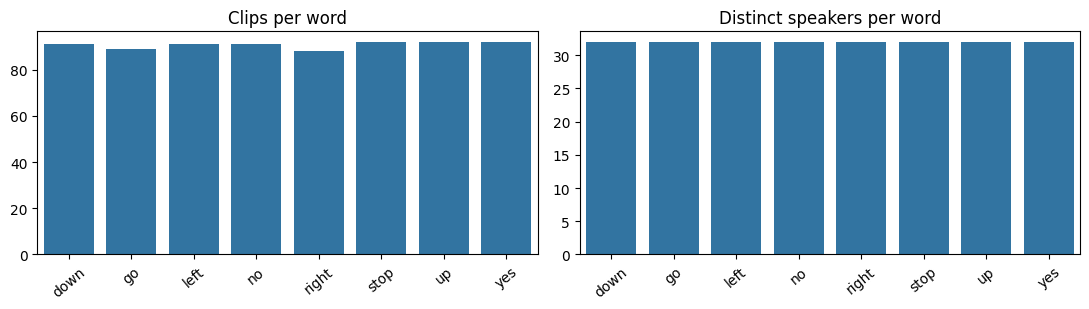

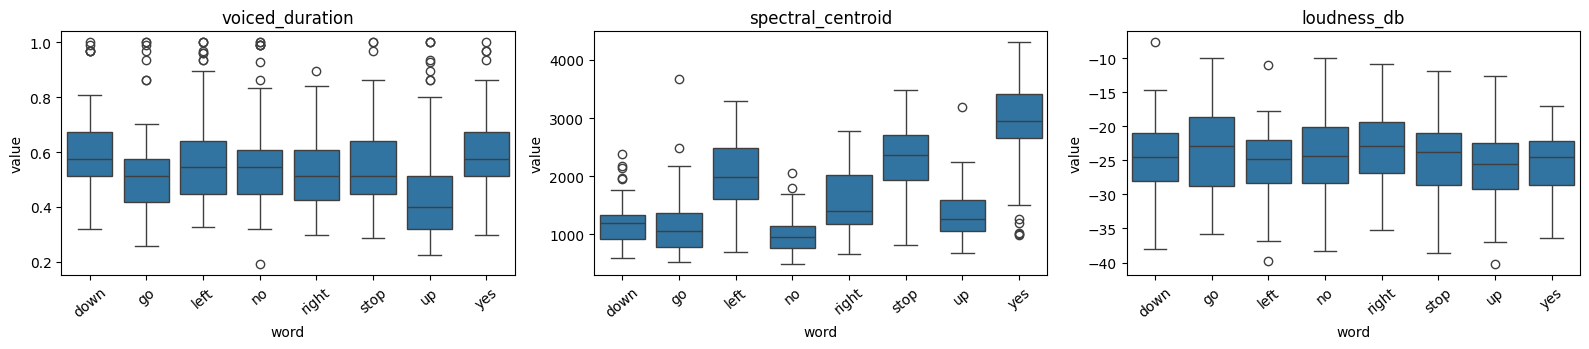

- **Class balance:** 'stop' has 92 clips, 'right' has 88 (1.0x). Roughly balanced, so accuracy is a fair headline metric. Speakers per word: 32 to 32; more distinct voices means a model that generalises to new people.

- **Spoken duration (seconds, silence trimmed):** highest for 'down' (0.60), lowest for 'up' (0.46). A real difference (32%), consistent with longer words such as multi-syllable numbers take more time to say.

- **Spectral centroid (Hz, the 'brightness' of the sound):** highest for 'yes' (2942.20), lowest for 'no' (995.52). A real difference (196%), consistent with fricatives like 's' and 'ch' push energy to higher frequencies than vowels do.

- **Loudness (dB):** highest for 'right' (-23.58), lowest for 'up' (-26.03). Classes look alike here, so this feature alone cannot identify the word; the model must learn the time-frequency pattern.

In [3]:
classes = pp.get_class_names()
ins = pp.dataset_insights(max_per_class=100)
# Feature 1: class balance + speakers
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
sns.barplot(x=list(ins["counts"]), y=list(ins["counts"].values()), ax=ax[0]); ax[0].set_title("Clips per word"); ax[0].tick_params(axis="x", rotation=40)
sns.barplot(x=list(ins["speakers"]), y=list(ins["speakers"].values()), ax=ax[1]); ax[1].set_title("Distinct speakers per word"); ax[1].tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()

# Features 2-4: duration, spectral centroid, loudness
rows = [(c, f, v) for f, d in ins["features"].items() for c, vals in d.items() for v in vals]
df = pd.DataFrame(rows, columns=["word", "feature", "value"])
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, f in zip(axes, ["voiced_duration", "spectral_centroid", "loudness_db"]):
    sns.boxplot(data=df[df.feature == f], x="word", y="value", ax=ax); ax.set_title(f); ax.tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()
from IPython.display import Markdown
Markdown("\n\n".join("- " + n for n in ins["interpretations"]))

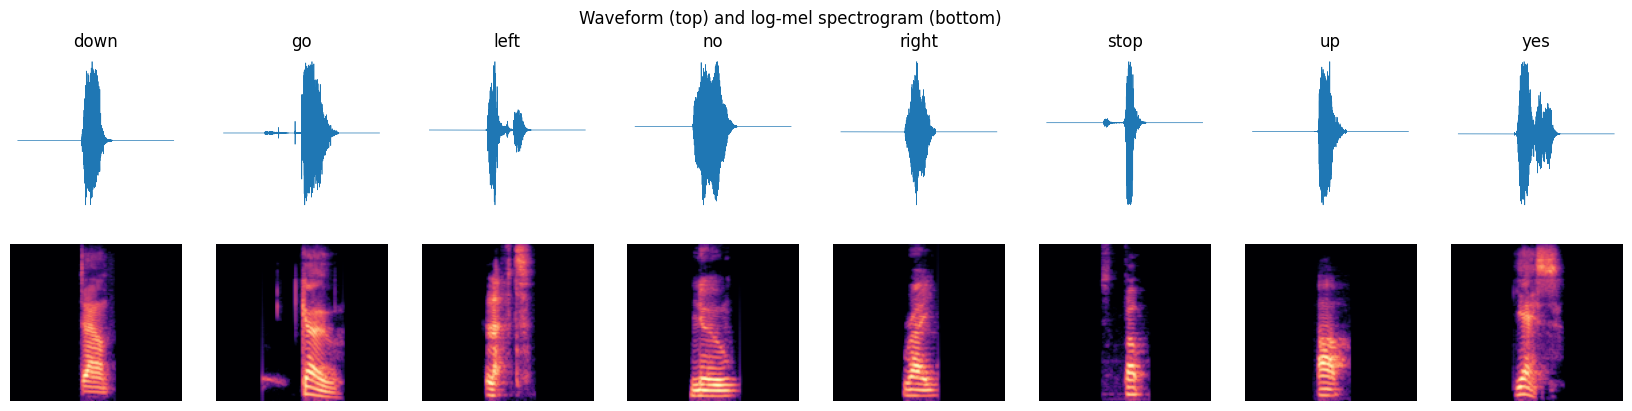

In [4]:
# One waveform + spectrogram per word
fig, axes = plt.subplots(2, len(classes), figsize=(2.6 * len(classes), 4.5))
for i, c in enumerate(classes):
    f = random.choice(pp.list_audio(pp.TRAIN_DIR / c))
    y = pp.trim_and_fit(pp.load_waveform(f))
    axes[0][i].plot(y, lw=0.5); axes[0][i].set_title(c); axes[0][i].axis("off")
    axes[1][i].imshow(pp.waveform_to_spec(y)[:, :, 0], origin="lower", aspect="auto", cmap="magma"); axes[1][i].axis("off")
plt.suptitle("Waveform (top) and log-mel spectrogram (bottom)"); plt.show()

### Interpretation of the data
Write what you SEE, then what it MEANS.

1. **Class balance and speakers** (plot: clips and speakers per word)
   * I see: every word has almost the same number of training clips (about 88 to 92) and the same number of distinct speakers (about 32).
   * It means / what I do about it: the classes are balanced, so accuracy is a fair headline metric and no word is favoured. Having 32 different voices per word helps the model generalise to new people. I still use class weights and report precision, recall and F1 per word as a safeguard.

2. **Spoken duration** (box plot)
   * I see (which words are longest/shortest, how big is the spread): the typical spoken time is about 0.5 to 0.6 s for most words. "yes" and "down" are slightly longer, and "up" is the shortest (about 0.4 s). The boxes overlap a lot and there are many outliers near 1.0 s, which is the maximum clip length.
   * It means (syllables? speaking speed?): short one-syllable words like "up" take less time than words with more sounds, but speakers vary in speed, so duration alone cannot identify a word. It is a weak cue.

3. **Spectral centroid, the "brightness" of the sound** (box plot)
   * I see: "yes" is the brightest by far (median about 3000 Hz), then "stop" (about 2400 Hz) and "left" (about 2000 Hz). "no", "go", "down" and "up" are the lowest (about 1000 to 1300 Hz).
   * It means (which sounds carry high frequencies, do classes overlap?): the "s" and "t" sounds in "yes", "stop" and "left" put energy at high frequencies, while words dominated by vowels like "o" and "ow" sit lower. This is the most useful feature, but "no", "go", "down" and "up" overlap, so the model must use the full time-frequency pattern to separate them.

4. **Loudness** (box plot)
   * I see: all words have a similar median loudness (about -23 to -25 dB) with a very wide range, from about -40 to -10 dB.
   * It means (microphone distance? device?) and why we normalise it: the differences come from how far each speaker was from the microphone and which device they used, not from the word. That is why every clip is loudness-normalised in preprocessing, so the model learns the word and not the volume.

5. **Spectrograms** (waveform + spectrogram per word)
   * Which two words look most alike, and which look most different: "down", "up" and "no" look alike, with one short block of energy at lower frequencies. "go" and "no" are especially close because they differ only in the first sound. "yes" and "stop" look most different: "yes" has energy reaching high frequencies in two parts, and "stop" has noisy bursts spread across frequencies.
   * What this predicts about which words the model will confuse: I expect confusion between "go" and "no" and between "down" and "up", while "yes" and "stop" should be recognised more easily.

## 4. Preprocessing
| Step | Why |
|---|---|
| Read audio, convert to mono, resample to 16 kHz | one consistent format for every phone / microphone |
| Trim leading/trailing silence, centre the word in a 2 s window | recordings start at random moments; fixed-size input |
| 128-band log-mel spectrogram (`n_fft=1024`, `hop=250`) | turns sound into a 128x128 image a CNN can read |
| Per-clip loudness normalisation, scale to [-1, 1] | removes microphone-distance effects |
| Validation split **by speaker** | no voice appears in both training and validation |
| Augmentation (**training clips only**): time shift, gain, speed, pitch, noise + SpecAugment masks | more voices/conditions from few recordings |
| Class weights | compensate for class imbalance |
What I see in the augmented spectrograms below compared with the original: the original shows the word centred with silence (black) on both sides.
 In the augmented versions the word sits in a different place and takes up a different width, because the clip was shifted in time or sped up/slowed down. The background looks brighter and noisier (pink instead of black), because of the added noise and gain change.
 Each augmented version also has a thin black horizontal band at a different height, which is the SpecAugment mask that hides a few frequency bands. The word's overall pattern is still recognisable in every copy, but each one looks like a different recording, which gives the model more variety to learn from.

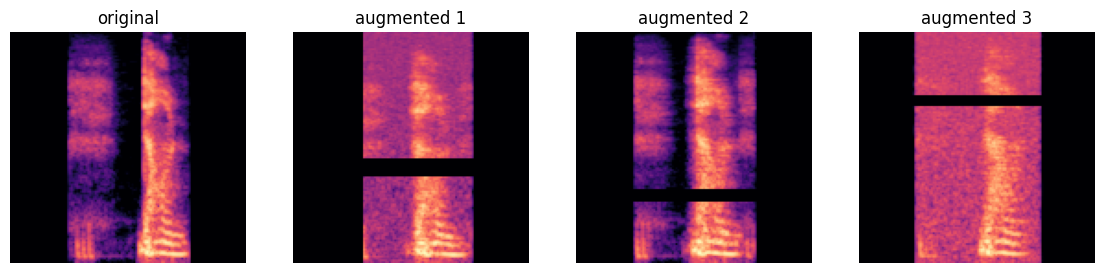

classes: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']
training clips incl. augmentation: 2280
class weights: {0: 1.0035211267605635, 1: 1.0178571428571428, 2: 0.9895833333333334, 3: 0.9895833333333334, 4: 1.0326086956521738, 5: 0.9895833333333334, 6: 0.9895833333333334, 7: 0.9895833333333334}


In [5]:
f = random.choice(pp.list_audio(pp.TRAIN_DIR / classes[0]))
raw = pp.load_waveform(f); fitted = pp.trim_and_fit(raw)
rng = random.Random(1)
variants = [("original", pp.waveform_to_spec(fitted)[:, :, 0])]
for k in range(3):
    a = pp.spec_augment(pp.waveform_to_spec(pp.trim_and_fit(pp.augment_waveform(raw, rng))), rng)
    variants.append((f"augmented {k+1}", a[:, :, 0]))
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, (t, s) in zip(axes, variants):
    ax.imshow(s, origin="lower", aspect="auto", cmap="magma"); ax.set_title(t); ax.axis("off")
plt.show()

class_names = pp.get_class_names()
train_ds, val_ds, ytr = mdl.prepare_data(class_names)
class_weights = mdl._class_weights(ytr, len(class_names))
print("classes:", class_names); print("training clips incl. augmentation:", len(ytr)); print("class weights:", class_weights)

## 5. Baseline: vanilla CNN (no pre-training, no augmentation, no regularisation tricks)

In [6]:
from tensorflow.keras import layers
baseline = tf.keras.Sequential([
    tf.keras.Input(shape=(*pp.SPEC_SHAPE, 1)),
    layers.Conv2D(16, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(), layers.Dense(64, activation="relu"), layers.Dense(len(class_names), activation="softmax"),
], name="vanilla_cnn")
mdl.compile_model(baseline, 1e-3)
_aug = mdl.AUG_FACTOR; mdl.AUG_FACTOR = 0                      # no augmentation for the baseline
b_train, b_val, _ = mdl.prepare_data(class_names); mdl.AUG_FACTOR = _aug
h_base = baseline.fit(b_train, validation_data=b_val, epochs=max(5, EPOCHS // 2), verbose=2)

Epoch 1/7
18/18 - 10s - 552ms/step - accuracy: 0.2404 - loss: 2.1768 - val_accuracy: 0.4103 - val_loss: 1.8242
Epoch 2/7
18/18 - 6s - 322ms/step - accuracy: 0.5105 - loss: 1.4498 - val_accuracy: 0.7051 - val_loss: 1.0624
Epoch 3/7
18/18 - 12s - 675ms/step - accuracy: 0.7088 - loss: 0.8285 - val_accuracy: 0.7244 - val_loss: 0.9866
Epoch 4/7
18/18 - 14s - 764ms/step - accuracy: 0.7842 - loss: 0.6233 - val_accuracy: 0.7692 - val_loss: 0.8130
Epoch 5/7
18/18 - 6s - 332ms/step - accuracy: 0.8404 - loss: 0.4546 - val_accuracy: 0.7500 - val_loss: 0.7963
Epoch 6/7
18/18 - 8s - 422ms/step - accuracy: 0.8719 - loss: 0.3775 - val_accuracy: 0.7372 - val_loss: 0.9090
Epoch 7/7
18/18 - 6s - 328ms/step - accuracy: 0.9193 - loss: 0.2724 - val_accuracy: 0.7821 - val_loss: 0.8327


## 6. Optimised models
**A. MobileNetV2 transfer learning** (ImageNet weights, two-stage fine-tuning) and **B. a regularised CNN trained
from scratch**. Both use: dropout, L2, Adam, early stopping, ReduceLROnPlateau, class weights, augmentation.
We keep whichever scores best on the held-out test speakers.

In [7]:
# A. MobileNetV2: stage 1 (head only) then stage 2 (fine-tune top 30 layers)
mobilenet = mdl.build_model(len(class_names)) if mdl.ARCH != "cnn" else None
if mobilenet is None:
    mdl.ARCH = "mobilenet"; mobilenet = mdl.build_model(len(class_names))
mdl.compile_model(mobilenet, 1e-3)
hA1 = mobilenet.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, class_weight=class_weights, callbacks=mdl._callbacks(4), verbose=2)
mdl.unfreeze_top(mobilenet, 30); mdl.compile_model(mobilenet, 1e-5)
hA2 = mobilenet.fit(train_ds, validation_data=val_ds, epochs=FT_EPOCHS, class_weight=class_weights, callbacks=mdl._callbacks(3), verbose=2)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/15
72/72 - 39s - 535ms/step - accuracy: 0.1842 - loss: 2.2055 - val_accuracy: 0.3974 - val_loss: 1.7111 - learning_rate: 0.0010
Epoch 2/15
72/72 - 33s - 465ms/step - accuracy: 0.2425 - loss: 1.9338 - val_accuracy: 0.4615 - val_loss: 1.5235 - learning_rate: 0.0010
Epoch 3/15
72/72 - 31s - 424ms/step - accuracy: 0.2978 - loss: 1.8465 - val_accuracy: 0.4936 - val_loss: 1.4739 - learning_rate: 0.0010
Epoch 4/15
72/72 - 31s - 426ms/step - accuracy: 0.3079 - loss: 1.7837 - val_accuracy: 0.4679 - val_loss: 1.3802 - learning_rate: 0.0010
Epoch 5/15
72/72 - 42s - 580ms/step - accuracy: 0.3421 - loss: 1.7201 - val_accuracy: 0.4744 - val_loss: 1.3960 - learning_rate: 0.0010
Epoch 6/15
72/72 - 32s - 439ms/step - accuracy: 0.3684 - loss: 1.6622 - val_accuracy: 0.5064 - val_loss: 1.3482 - learning_rate: 0.0010
Epoch 7/15
72/72 - 30s - 423ms/step - accuracy: 0.3811 - loss: 1.6325 - val_accuracy: 0.5321 - val_loss: 1.3011 - learning_rate: 0.0010

In [8]:
# B. Regularised CNN from scratch
cnn = mdl.build_cnn(len(class_names)); mdl.compile_model(cnn, 1e-3)
hB = cnn.fit(train_ds, validation_data=val_ds, epochs=EPOCHS + 5, class_weight=class_weights, callbacks=mdl._callbacks(5), verbose=2)

Epoch 1/20
72/72 - 84s - 1s/step - accuracy: 0.1851 - loss: 2.1048 - val_accuracy: 0.3590 - val_loss: 1.8936 - learning_rate: 0.0010
Epoch 2/20
72/72 - 60s - 833ms/step - accuracy: 0.3088 - loss: 1.8632 - val_accuracy: 0.3462 - val_loss: 1.7340 - learning_rate: 0.0010
Epoch 3/20
72/72 - 83s - 1s/step - accuracy: 0.3746 - loss: 1.6717 - val_accuracy: 0.4423 - val_loss: 1.5436 - learning_rate: 0.0010
Epoch 4/20
72/72 - 60s - 834ms/step - accuracy: 0.4750 - loss: 1.4407 - val_accuracy: 0.5256 - val_loss: 1.3951 - learning_rate: 0.0010
Epoch 5/20
72/72 - 82s - 1s/step - accuracy: 0.6057 - loss: 1.1445 - val_accuracy: 0.6603 - val_loss: 1.0601 - learning_rate: 0.0010
Epoch 6/20
72/72 - 61s - 851ms/step - accuracy: 0.6904 - loss: 0.9313 - val_accuracy: 0.4679 - val_loss: 1.3282 - learning_rate: 0.0010
Epoch 7/20
72/72 - 60s - 830ms/step - accuracy: 0.7596 - loss: 0.7489 - val_accuracy: 0.7436 - val_loss: 0.7357 - learning_rate: 0.0010
Epoch 8/20
72/72 - 82s - 1s/step - accuracy: 0.8136 - los

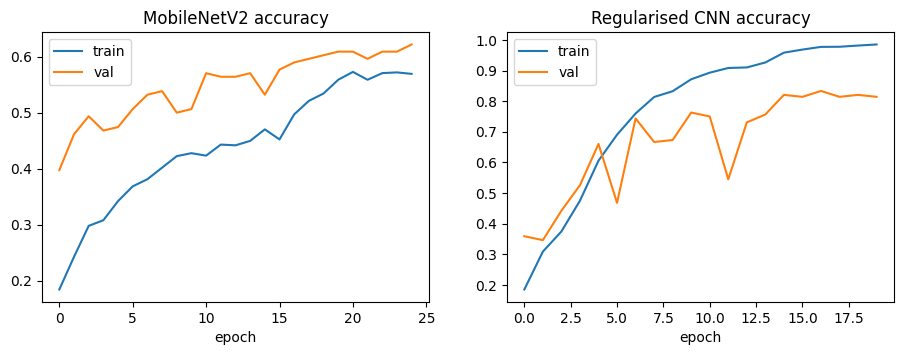

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
histA = {k: hA1.history[k] + hA2.history[k] for k in hA1.history}
ax[0].plot(histA["accuracy"], label="train"); ax[0].plot(histA["val_accuracy"], label="val"); ax[0].set_title("MobileNetV2 accuracy")
ax[1].plot(hB.history["accuracy"], label="train"); ax[1].plot(hB.history["val_accuracy"], label="val"); ax[1].set_title("Regularised CNN accuracy")
for a in ax: a.legend(); a.set_xlabel("epoch")
plt.show()

## 7. Model testing / evaluation (accuracy, loss, precision, recall, F1, ROC-AUC, confusion matrix)

In [10]:
# MODEL SELECTION uses the VALIDATION split (speakers held out of training). The TEST set is only used to REPORT.
Xva = np.concatenate([x.numpy() for x, _ in val_ds]); yva = np.concatenate([y.numpy() for _, y in val_ds])
files, labels = pp.list_labelled(pp.TEST_DIR, class_names)
Xte, y_true = pp.arrays_from_files(files, labels)

def full_eval(m, X, y):
    probs = m.predict(X, verbose=0); y_pred = probs.argmax(1)
    loss, acc = m.evaluate(X, y, verbose=0)
    p, r, f1, _ = precision_recall_fscore_support(y, y_pred, average="weighted", zero_division=0)
    try: auc = roc_auc_score(y, probs, multi_class="ovr", labels=list(range(len(class_names))))
    except Exception: auc = float("nan")
    return {"accuracy": acc, "loss": loss, "precision": p, "recall": r, "f1": f1, "roc_auc": auc}, y_pred

models = {"Vanilla CNN": baseline, "MobileNetV2 (transfer)": mobilenet, "Regularised CNN": cnn}
val_table = pd.DataFrame({n: full_eval(m, Xva, yva)[0] for n, m in models.items()}).T.round(4)
best_name = val_table["f1"].idxmax()
print("Validation results (used to choose the model):"); display(val_table)
print("\nBest model by VALIDATION F1:", best_name)

test_res, test_pred = {}, {}
for n, m in models.items(): test_res[n], test_pred[n] = full_eval(m, Xte, y_true)
table = pd.DataFrame(test_res).T.round(4)
print("\nTEST results on unseen speakers (reported once, not used for selection):"); table

Validation results (used to choose the model):


,accuracy,loss,precision,recall,f1,roc_auc
Vanilla CNN,0.7821,0.8327,0.7970,0.7821,0.7742,0.9625
MobileNetV2 (transfer),0.6218,1.1451,0.6382,0.6218,0.6129,0.9145
Regularised CNN,0.8333,0.5919,0.8445,0.8333,0.8332,0.9779



Best model by VALIDATION F1: Regularised CNN

TEST results on unseen speakers (reported once, not used for selection):


,accuracy,loss,precision,recall,f1,roc_auc
Vanilla CNN,0.6597,1.3347,0.6973,0.6597,0.6645,0.9273
MobileNetV2 (transfer),0.4241,1.9133,0.4292,0.4241,0.4218,0.8150
Regularised CNN,0.7696,0.7665,0.7991,0.7696,0.7733,0.9668


              precision    recall  f1-score   support

        down       0.83      0.79      0.81        24
          go       0.58      0.88      0.70        24
        left       0.74      0.58      0.65        24
          no       0.48      0.57      0.52        23
       right       0.88      0.96      0.92        24
        stop       0.95      0.75      0.84        24
          up       0.92      0.96      0.94        24
         yes       1.00      0.67      0.80        24

    accuracy                           0.77       191
   macro avg       0.80      0.77      0.77       191
weighted avg       0.80      0.77      0.77       191



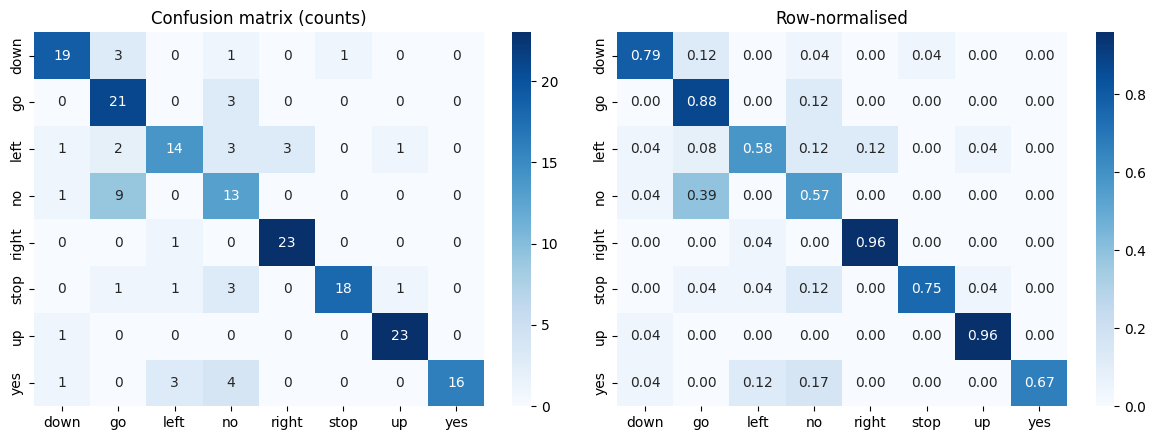

In [11]:
best_model, y_pred = models[best_name], test_pred[best_name]
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0]); ax[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[1]); ax[1].set_title("Row-normalised")
plt.tight_layout(); plt.show()

### How good is the model?
* Validation F1 of the three models: baseline 0.774 | MobileNetV2 0.613 | regularised CNN 0.833 -> chosen: Regularised CNN
* Test accuracy / precision / recall / F1 / ROC-AUC of the chosen model: 0.770 / 0.799 / 0.770 / 0.773 / 0.967 (on 191 clips from 8 speakers never used in training)
* Did the optimised models beat the baseline? By how much, and which technique probably helped most
  (transfer learning, augmentation, dropout, early stopping, class weights)? The regularised CNN beat the baseline: test accuracy 0.770 vs 0.660 and test F1 0.773 vs 0.665, about 11 points better. Its extra techniques (augmentation, dropout, L2, batch normalisation, early stopping, class weights) probably helped most, because the baseline has none of them. MobileNetV2 transfer learning did NOT help: it scored worse than the baseline (test F1 0.422). Its curves were still rising at epoch 25, so it was still under-trained, and ImageNet features, learned on photos, did not transfer well to spectrograms in my setup.
* Training vs validation curves: is there overfitting (train accuracy far above validation)? Yes, partly. The regularised CNN reaches about 0.98 training accuracy but only about 0.81 validation accuracy, and the validation curve is noisy because it contains only a few speakers. The test score (0.77) is also lower than validation (0.83), which shows that new voices are hard. The baseline overfits more (0.92 vs 0.78).
* Confusion matrix: the two words confused most are "no" and "go". Likely reason (similar sounds,
  similar length, speaker voice, noise): 9 of 23 "no" clips were predicted as "go" (39%), and 3 "go" clips as "no". The two words rhyme and differ only in the first consonant, so their spectrograms are very similar. "yes" and "left" were also sometimes predicted as "no".
* Which word is best recognised and which is worst (see the classification report): the best are "up" (F1 0.94) and "right" (recall 0.96, F1 0.92). The worst is "no" (only 13 of 23 correct, recall 0.57), followed by "left" (recall 0.58).
* What a wrong answer means for a learner using the app, and how the confidence score can help: a wrong answer means the learner is told to try again or gets the wrong response, which is frustrating but not harmful. The confidence score lets the app ask the learner to repeat the word when confidence is low, and it can warn when the prediction is "go" or "no", the two words the model mixes up most.

## 8. Prediction function

In [12]:
metrics = mdl._save(best_model, class_names, mdl.evaluate_model(best_model, class_names), "train")
pp.log_run("train", "success", metrics["version"], metrics["accuracy"], metrics["f1"], len(ytr), note=f"notebook: {best_name}")
print("saved:", mdl.MODEL_PATH, "| version", metrics["version"], "| chose:", best_name)
prediction.reload_model()

def predict_file(path):
    r = prediction.predict_audio(open(path, "rb").read())
    return r["label"], round(r["confidence"], 3)

sample = random.sample(pp.list_audio(pp.TEST_DIR), min(8, len(pp.list_audio(pp.TEST_DIR))))
for f in sample:
    label, conf = predict_file(f)
    print(f"true: {f.parent.name:10s} predicted: {label:10s} confidence: {conf}   {'OK' if label == f.parent.name else 'WRONG'}")

saved: /content/spoken-word-mlops/models/spoken_words_mobilenetv2.h5 | version 1 | chose: Regularised CNN
true: down       predicted: down       confidence: 0.996   OK
true: left       predicted: down       confidence: 0.502   WRONG
true: go         predicted: no         confidence: 0.718   WRONG
true: right      predicted: right      confidence: 0.998   OK
true: left       predicted: left       confidence: 0.938   OK
true: right      predicted: right      confidence: 1.0   OK
true: up         predicted: up         confidence: 1.0   OK
true: no         predicted: no         confidence: 0.759   OK


## 9. Retraining demo
Simulates the UI: **new recordings from new speakers** (folder `new_recordings/`, speakers never seen in training and
never part of the test set) are uploaded, validated, saved to `data/train` and logged in the SQLite database. Retraining
then **loads the saved model as the pre-trained model** and fine-tunes it on the enlarged dataset. The test set is
untouched, so before/after scores are comparable.

In [13]:
NEW_DIR = Path(os.getenv("NEW_DIR", "new_recordings"))
assert NEW_DIR.is_dir(), f"'{NEW_DIR}' not found: run scripts/prepare_speech_commands.py"
before = mdl.load_metrics()
n_ok = n_bad = 0
for c in class_names:
    for f in pp.list_audio(NEW_DIR / c):
        r = pp.save_uploaded_files([(f.name, f.read_bytes())], c, speaker=pp.speaker_of(f))
        n_ok += r["saved"]; n_bad += len(r["rejected"])
print(f"uploaded {n_ok} clips, rejected {n_bad} | pending (not yet used for training): {pp.pending_upload_count()}")

import sqlite3
con = sqlite3.connect(pp.DB_PATH)
print("\nUploads stored in the database:")
display(pd.read_sql("SELECT id, filename, label, speaker, uploaded_at, used_in_training FROM uploads ORDER BY id DESC LIMIT 8", con))
display(pd.read_sql("SELECT label, speaker, COUNT(*) AS clips FROM uploads GROUP BY label, speaker", con).head(12))

after = mdl.retrain(epochs=6)
pp.log_run("retrain", "success", after["version"], after["accuracy"], after["f1"], note="notebook demo")
print("\npending after retraining:", pp.pending_upload_count())
display(pd.DataFrame({"before retraining": {k: before[k] for k in ["version", "accuracy", "loss", "f1"]},
                      "after retraining": {k: after[k] for k in ["version", "accuracy", "loss", "f1"]}}))
display(pd.DataFrame(pp.list_runs()))

uploaded 143 clips, rejected 0 | pending (not yet used for training): 143

Uploads stored in the database:


,id,filename,label,speaker,uploaded_at,used_in_training
0,143,f953e1af__3.wav,yes,f953e1af,2026-11-23T15:09:55+00:00,0
1,142,f953e1af__2.wav,yes,f953e1af,2026-11-23T15:09:55+00:00,0
2,141,f953e1af__1.wav,yes,f953e1af,2026-11-23T15:09:55+00:00,0
3,140,f5341341__3.wav,yes,f5341341,2026-11-23T15:09:55+00:00,0
4,139,f5341341__2.wav,yes,f5341341,2026-11-23T15:09:55+00:00,0
5,138,f5341341__1.wav,yes,f5341341,2026-11-23T15:09:55+00:00,0
6,137,c93d5e22__3.wav,yes,c93d5e22,2026-11-23T15:09:55+00:00,0
7,136,c93d5e22__2.wav,yes,c93d5e22,2026-11-23T15:09:55+00:00,0


,label,speaker,clips
0,down,0e6e36c9,3
1,down,4c6944d6,3
2,down,9b02d503,3
3,down,c93d5e22,3
4,down,f5341341,3
5,down,f953e1af,3
6,go,0e6e36c9,3
7,go,4c6944d6,3
8,go,9b02d503,3
9,go,c93d5e22,3


Epoch 1/6
85/85 - 80s - 938ms/step - accuracy: 0.8331 - loss: 0.5534 - val_accuracy: 0.9479 - val_loss: 0.2643 - learning_rate: 1.0000e-05
Epoch 2/6
85/85 - 81s - 958ms/step - accuracy: 0.8401 - loss: 0.5363 - val_accuracy: 0.9427 - val_loss: 0.2559 - learning_rate: 1.0000e-05
Epoch 3/6
85/85 - 82s - 967ms/step - accuracy: 0.8408 - loss: 0.5309 - val_accuracy: 0.9427 - val_loss: 0.2694 - learning_rate: 1.0000e-05
Epoch 4/6
85/85 - 82s - 960ms/step - accuracy: 0.8323 - loss: 0.5247 - val_accuracy: 0.9427 - val_loss: 0.2671 - learning_rate: 1.0000e-05
Epoch 5/6
85/85 - 81s - 951ms/step - accuracy: 0.8419 - loss: 0.5120 - val_accuracy: 0.9427 - val_loss: 0.2712 - learning_rate: 3.0000e-06



pending after retraining: 0


,before retraining,after retraining
version,1.000000,2.000000
accuracy,0.769634,0.785340
loss,0.766473,0.764441
f1,0.773276,0.789029


,id,kind,started_at,finished_at,status,version,accuracy,f1,n_train_clips,note
0,2,retrain,2026-11-23T15:17:59+00:00,2026-11-23T15:17:59+00:00,success,2,0.785340,0.789029,NaN,notebook demo
1,1,train,2026-11-23T15:07:37+00:00,2026-11-23T15:07:37+00:00,success,1,0.769634,0.773276,2280.0,notebook: Regularised CNN


### Retraining results
* New clips uploaded: 143 from 6 new speakers (the speakers were never in the main dataset or the test set). Version before -> after: 1 -> 2
* Accuracy / F1 before: 0.770 / 0.773 ; after: 0.785 / 0.789 . Better, same or worse? Slightly better (about +1.6 points on both). Test loss stayed almost the same (0.766 -> 0.764).
* Why (more voices? small number of new clips? too few epochs?) The new data is small: 143 clips from 6 voices added to about 570 original training clips from 32 voices. Retraining also uses a low learning rate (1e-5) so the saved model is only gently adjusted, and early stopping ended it after 5 epochs. A 1.6-point gain is only about 3 of the 191 test clips, so it is a small improvement and could partly be noise. It shows that retraining works and does not make the model worse. More new voices would help more.
* The two retraining triggers in my system: (1) the Retrain button in the UI, which calls the API's /retrain endpoint (2) automatic retraining when 30 or more new clips are pending after an upload (RETRAIN_THRESHOLD = 30)

## 10. Conclusion
* Best model: the regularised CNN, with test accuracy 0.770 and F1 0.773 on speakers it had never heard. After retraining on 143 new clips from 6 new voices it reached accuracy 0.785 and F1 0.789.
* What worked best: a CNN trained from scratch with augmentation, dropout, L2, batch normalisation, early stopping and class weights, which beat the vanilla baseline by about 11 points. What surprised me: MobileNetV2 transfer learning, pre-trained on photos, did worse than the simple baseline (test F1 0.42), and most errors came from just two words, "no" and "go".
* The full pipeline: recordings -> preprocessing -> model -> evaluation -> saved `.h5` -> FastAPI -> Streamlit
  (predict, visualisations, bulk upload, retrain) -> Docker + load balancer -> cloud -> Locust tests.
* **Limitations (my own):** only 8 English words and 1-second clips; about 77 to 79% accuracy is not yet good enough for real use; the test set has only 8 speakers (191 clips), so the score is a rough estimate; the recordings are crowd-sourced with uneven noise and microphones; "no", "left" and "yes" are often mixed up; I did not run an extensive hyperparameter search; and the retraining gain was small.
* **Next steps:** add more speakers and more words, add background-noise augmentation, try a model pre-trained on audio (not on photos), use the confidence score to ask the user to repeat when it is low, and retrain on Kinyarwanda recordings.
* Who this helps and how it could be used in a learning app: learners who cannot easily use a screen or keyboard (blind or low-vision learners, young children, low-literacy adults) could answer or navigate a learning app by voice. Because the pipeline is retrainable, the same system could later learn Kinyarwanda words from new recordings.